# 07 · Final evaluation and model export

The test split is used here for the first and only time. Every model uses the settings chosen on
validation in notebooks 05 and 06. Three settings:

1. **Warm** - recover the 20% of each playlist that was held out;
2. **Short playlists** - the same targets, but each playlist shows only 3 seed tracks;
3. **New releases** - rank the 1,824 tracks never seen in training; targets are the playlists that added them.

At the end, the models are refit on all playlists and saved for the console app.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
FIG = config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)
import json
from sklearn.preprocessing import StandardScaler
from src.data.load import load_catalog
from src import artifacts
from src.features.interaction_matrix import load_splits, short_playlists, InteractionMatrixBuilder
from src.evaluation.metrics import evaluate, compare
from src.models.baselines import PopularityRecommender, RandomRecommender
from src.models.content import ContentRecommender
from src.models.collaborative import ItemKNN, ALSRecommender, BPRRecommender
from src.models.hybrid import HybridRecommender, HardThresholdRouter

tracks = load_catalog()
feats = artifacts.load_features()
E = feats["embeddings"]
splits = load_splits()
train, val, test, cold_test, cold = splits["train"], splits["val"], splits["test"], splits["cold_test"], splits["cold_items"]
params = json.loads((config.DATA_PROCESSED / "best_params.json").read_text())
hp = json.loads((config.DATA_PROCESSED / "hybrid_params.json").read_text())
print("content blocks:", params["blocks"]); print("hybrid:", hp)

# train on train only; val edges are known history at test time, so they are excluded from rankings too
pop = PopularityRecommender().fit(train)
content = ContentRecommender(E, name="Content (audio + genre + text)")
knn = ItemKNN(**params["knn"]).fit(train)
als = ALSRecommender(**params["als"]).fit(train)
bpr = BPRRecommender(**params["bpr"]).fit(train)
hybrid = HybridRecommender(knn, als, content, pop, **hp).fit(train)
models = {
    "Random": RandomRecommender().fit(train),
    "Popularity": pop,
    "Content (text only, original)": ContentRecommender(feats["text"]),
    "Content (raw audio)": ContentRecommender(StandardScaler().fit_transform(tracks[config.AUDIO_FEATURES])),
    "Content (engineered)": content,
    "Item-kNN": knn, "ALS": als, "BPR": bpr,
    "Original hard router": HardThresholdRouter(als, content, pop).fit(train),
    "Hybrid": hybrid,
}
seen = train + val
short, short_users = short_playlists(train)

content blocks: {'audio': 1.0, 'genre': 16.0, 'text': 0.3}
hybrid: {'kappa': 1.0, 'cf_mix': 0.3, 'w_content': 0.5, 'w_pop': 0.0, 'kappa_user': 400.0}


In [2]:
pv = tracks.popularity.values
warm = {n: evaluate(m, train, test, exclude=seen, embeddings=E, popularity=pv) for n, m in models.items()}
shortr = {n: evaluate(m, short, test, exclude=seen, users=short_users) for n, m in models.items()}
coldr = {n: evaluate(m, train, cold_test, exclude=seen, candidates=cold) for n, m in models.items()}
print("1. Warm tracks (test)")
compare(warm)

1. Warm tracks (test)


,recall@10,ndcg@10,hit@10,recall@20,ndcg@20,hit@20,coverage@10,avg_popularity@10,diversity@10
Random,0.0004,0.0003,0.0025,0.0008,0.0005,0.0055,0.9282,51.9414,0.5937
Popularity,0.0034,0.0030,0.0207,0.0058,0.0041,0.0380,0.0007,77.9479,0.3929
"Content (text only, original)",0.0110,0.0098,0.0625,0.0178,0.0128,0.1005,0.4577,53.9211,0.4444
Content (raw audio),0.0065,0.0060,0.0452,0.0125,0.0087,0.0860,0.4878,53.6946,0.3167
Content (engineered),0.0384,0.0334,0.2165,0.0666,0.0461,0.3452,0.4135,55.4337,0.0370
Item-kNN,0.0752,0.0688,0.3692,0.1206,0.0892,0.5342,0.3988,59.3724,0.0868
ALS,0.0679,0.0620,0.3430,0.1136,0.0828,0.5183,0.3747,60.1928,0.0975
BPR,0.0524,0.0471,0.2768,0.0891,0.0638,0.4357,0.4310,57.6812,0.0802
Original hard router,0.0331,0.0297,0.1845,0.0544,0.0391,0.2883,0.3988,52.5924,0.0405
Hybrid,0.0795,0.0726,0.3920,0.1242,0.0927,0.5510,0.3336,60.4940,0.0777


In [3]:
print("2. Short playlists, 3 seed tracks (test)")
display(compare(shortr)[["recall@10", "recall@20", "ndcg@10", "hit@10"]])
print("3. New releases (test)")
compare(coldr)[["recall@10", "recall@20", "ndcg@10", "hit@10", "coverage@10"]]

2. Short playlists, 3 seed tracks (test)


,recall@10,recall@20,ndcg@10,hit@10
Random,0.0006,0.0009,0.0007,0.0037
Popularity,0.0031,0.0055,0.0029,0.0205
"Content (text only, original)",0.0075,0.0120,0.0070,0.0462
Content (raw audio),0.0046,0.0083,0.0039,0.0323
Content (engineered),0.0331,0.0581,0.0290,0.1902
Item-kNN,0.0494,0.0777,0.0463,0.2722
ALS,0.0611,0.0983,0.0557,0.3200
BPR,0.0474,0.0815,0.0433,0.2636
Original hard router,0.0031,0.0055,0.0029,0.0205
Hybrid,0.0613,0.0974,0.0574,0.3221


3. New releases (test)


,recall@10,recall@20,ndcg@10,hit@10,coverage@10
Random,0.0038,0.0086,0.0027,0.0158,1.0000
Popularity,0.0093,0.0176,0.0059,0.0315,0.0055
"Content (text only, original)",0.0542,0.0880,0.0390,0.1504,0.9441
Content (raw audio),0.0617,0.1047,0.0405,0.1747,0.9123
Content (engineered),0.2987,0.4574,0.2035,0.5901,0.8975
Item-kNN,0.0093,0.0176,0.0059,0.0315,0.0055
ALS,0.0093,0.0176,0.0059,0.0315,0.0055
BPR,0.0093,0.0176,0.0059,0.0315,0.0055
Original hard router,0.2987,0.4574,0.2035,0.5901,0.8975
Hybrid,0.2987,0.4574,0.2035,0.5901,0.8975


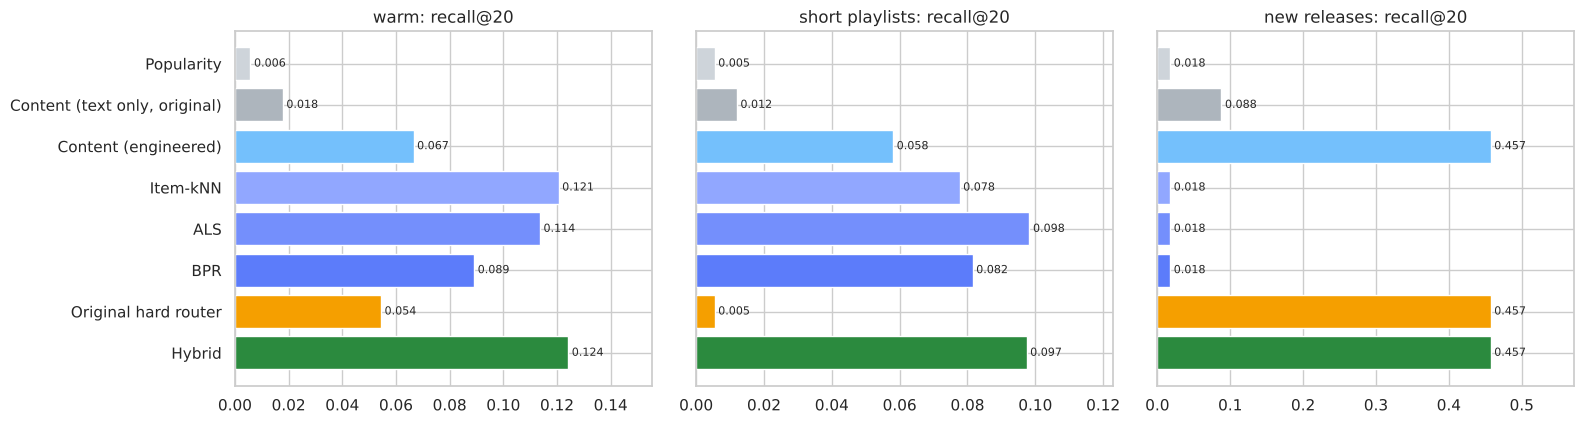

,warm,short playlists,new releases
Popularity,0.0058,0.0055,0.0176
"Content (text only, original)",0.0178,0.0120,0.0880
Content (engineered),0.0666,0.0581,0.4574
Item-kNN,0.1206,0.0777,0.0176
ALS,0.1136,0.0983,0.0176
BPR,0.0891,0.0815,0.0176
Original hard router,0.0544,0.0055,0.4574
Hybrid,0.1242,0.0974,0.4574


In [4]:
summary = pd.DataFrame({"warm": {n: r["recall@20"] for n, r in warm.items()},
                        "short playlists": {n: r["recall@20"] for n, r in shortr.items()},
                        "new releases": {n: r["recall@20"] for n, r in coldr.items()}})
order = ["Popularity", "Content (text only, original)", "Content (engineered)", "Item-kNN", "ALS", "BPR", "Original hard router", "Hybrid"]
colors = ["#ced4da", "#adb5bd", "#74c0fc", "#91a7ff", "#748ffc", "#5c7cfa", "#f59f00", "#2b8a3e"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for ax, col in zip(axes, summary.columns):
    v = summary.loc[order, col]
    ax.barh(order, v, color=colors)
    ax.set_title(f"{col}: recall@20"); ax.invert_yaxis()
    for i, x in enumerate(v):
        ax.text(x, i, f" {x:.3f}", va="center", fontsize=8)
    ax.set_xlim(0, v.max() * 1.25)
plt.tight_layout(); plt.savefig(FIG / "07_results.png"); plt.show()
summary.loc[order].round(4)

### Reading the results

* **Warm:** the hybrid is best on every accuracy metric (recall@20 0.124), a few percent above
  item-kNN alone and 2.3x the original hard-threshold router. That router does worse than plain CF
  because, with realistic long-tail play counts, it sends 78% of tracks to the content path.
* **Short playlists (3 seeds):** the hybrid and ALS are tied (0.097 vs 0.098). The original router
  scores the same as popularity, since it ignores playlists with fewer than 5 tracks.
* **New releases:** collaborative models cannot rank tracks with no plays and score like popularity.
  The engineered content embedding finds a playlist's new releases 5x more often than the original
  text-only embedding (recall@20 0.457 vs 0.088) and 4x more often than raw audio. The hybrid
  inherits this automatically because its CF weight is 0 for unplayed tracks.
* **Trade-off:** the hybrid covers less of the catalog in top-10 lists than item-kNN (33% vs 40%)
  and leans slightly more popular. The console app's diversity re-ranking and per-artist cap
  counter that at serving time.

## Accuracy against popularity bias and diversity

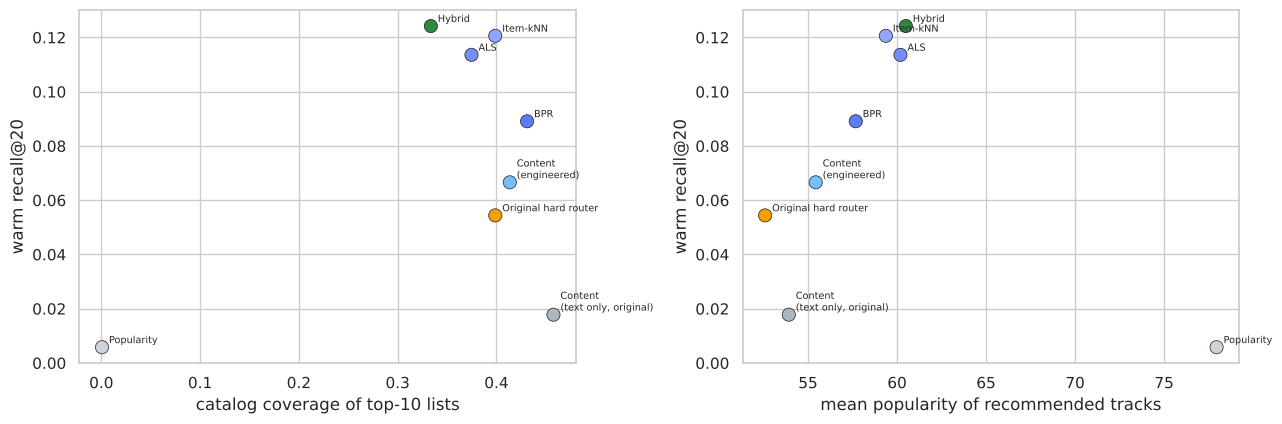

In [5]:
w = compare(warm).loc[order]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, col, label in [(axes[0], "coverage@10", "catalog coverage of top-10 lists"), (axes[1], "avg_popularity@10", "mean popularity of recommended tracks")]:
    ax.scatter(w[col], w["recall@20"], c=colors, s=90, edgecolor="k", lw=.5)
    for n, r in w.iterrows():
        ax.annotate(n.replace(" (", "\n("), (r[col], r["recall@20"]), fontsize=7, xytext=(5, 3), textcoords="offset points")
    ax.set(xlabel=label, ylabel="warm recall@20")
plt.tight_layout(); plt.savefig(FIG / "07_tradeoffs.png"); plt.show()

## Where the hybrid helps: by playlist length

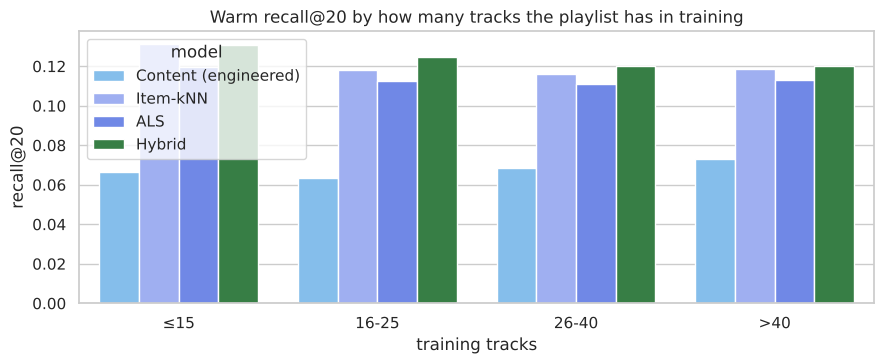

In [6]:
lengths = np.diff(train.indptr)
users = np.where(np.diff(test.indptr) > 0)[0]
buckets = pd.cut(lengths[users], [0, 15, 25, 40, 200], labels=["≤15", "16-25", "26-40", ">40"])
rows = []
for b in buckets.categories:
    u = users[buckets == b]
    for n in ["Content (engineered)", "Item-kNN", "ALS", "Hybrid"]:
        rows.append({"training tracks": b, "model": n, "recall@20": evaluate(models[n], train, test, exclude=seen, users=u, ks=(20,))["recall@20"]})
by_len = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.barplot(by_len, x="training tracks", y="recall@20", hue="model", ax=ax, palette=["#74c0fc", "#91a7ff", "#5c7cfa", "#2b8a3e"])
ax.set_title("Warm recall@20 by how many tracks the playlist has in training")
plt.tight_layout(); plt.savefig(FIG / "07_by_length.png"); plt.show()

## Example recommendations
✔ marks a track the playlist really contains in the held-out test set.

In [7]:
meta = pd.read_csv(config.PLAYLISTS)
for pid in [11, 404, 2024]:
    p = meta.iloc[pid]
    seeds = train[pid].indices
    s = hybrid.score(train[[pid]])[0]; s[seen[pid].indices] = -np.inf
    top = np.argsort(-s)[:8]
    held = set(test[pid].indices)
    print(f"\n{p.playlist_name}  ({len(seeds)} training tracks, taste: {p.taste_genres})")
    print("  seeds:", "; ".join(f"{tracks.track_name[i][:28]} - {tracks.main_artist[i]}" for i in seeds[:4]), "...")
    for i in top:
        print(f"   {'✔' if i in held else ' '} {tracks.track_name[i][:40]:<40} {tracks.main_artist[i][:22]:<22} {tracks.primary_genre[i]}")


Alternative & Black Metal Mix #11  (14 training tracks, taste: alternative;black-metal;alt-rock)
  seeds: Otherside - Red Hot Chili Peppers; Dani California - Red Hot Chili Peppers; This fffire - New Version - Franz Ferdinand; Drive - Incubus ...
     Shoot Me a Smile                         Red Hot Chili Peppers  funk
   ✔ I'm In Love With You                     The 1975               rock
     Youth of the Nation                      P.O.D.                 metal
     Snow (Hey Oh)                            Red Hot Chili Peppers  funk
     Moments Like This                        The Afters             alt-rock
     Higher                                   The Score              alt-rock
     Gladiator                                Zayde Wølf             alt-rock
     Everlong                                 Foo Fighters           grunge

J-Rock & J-Pop Mix #404  (16 training tracks, taste: j-rock;j-pop;anime)
  seeds: ベテルギウス - Yuuri; ポラリス - BLUE ENCOUNT; Brave Shine - Aimer; ラブレタ

## Refit on every playlist and save for the console app
After evaluation, the final models are trained on all interactions (train + val + test + new releases), the usual practice before serving.

In [8]:
inter = pd.read_csv(config.INTERACTIONS)
M = InteractionMatrixBuilder(tracks.track_uri.tolist()).build(inter)
pop_f = PopularityRecommender().fit(M)
final = HybridRecommender(ItemKNN(**params["knn"]).fit(M), ALSRecommender(**params["als"]).fit(M),
                          content, pop_f, **hp).fit(M)
artifacts.save_models({"hybrid": final, "interactions": M, "block_weights": params["blocks"],
                       "warm_results": warm, "short_results": shortr, "cold_results": coldr})
print("saved", config.MODELS.relative_to(config.PROJECT_ROOT), "->  run:  python cli.py")

saved data/processed/models.pkl ->  run:  python cli.py


## Summary

**What changed compared with the original project**

| | original | rebuilt |
|---|---|---|
| catalog rows | first genre per track, duplicates by title only | multi-genre labels kept, same-song duplicates merged, failed analyses dropped |
| content features | text only (TF-IDF, SBERT in code) | engineered audio (tempo folding, circle-of-fifths key, quantile transforms, weights) + learned genre map + text |
| playlists | genre chunks + popular tracks added to random playlists (CF test AUC 0.535) | simulated listeners with a documented taste model |
| CF model | LightFM (unmaintained, does not install on Python 3.12+) | item-kNN, ALS and BPR via `implicit`, all tuned on validation |
| cold start | hard thresholds, mixed score scales | z-scored soft blend weighted by track and playlist confidence |
| evaluation | one random split, precision@10 and AUC | warm / 3-seed / new-release settings, recall, NDCG, hit rate, coverage, popularity, diversity; validation for tuning, test once |
| interface | none | console app (`cli.py`) |

**What is real and what is simulated.** The tracks, audio features, genres and popularity are real
Spotify data. The playlists are simulated (notebook 04), so the CF and hybrid numbers say how well
each method recovers *that* behaviour, not how real Spotify users would respond. The numbers are not
comparable with the original notebook's AUC either, because both the data and the metrics changed.
To test on real behaviour, put real `pid, track_uri` rows in `data/processed/playlist_track_interactions.csv`
and re-run notebooks 04-07.